# Pricing Monte Carlo di una call asiatica sull'EURO STOXX 50 con tasso di interesse stocastico

## 1. Contesto e obiettivo
Il caso, collocato alla data di riferimento del **27 luglio 2026**, richiede la valutazione di un'opzione **call asiatica OTC a media aritmetica** sull'indice **EURO STOXX 50**, in un ambiente in cui sia il sottostante sia il tasso di interesse nominale evolvono congiuntamente in modo stocastico.

**Domanda quantitativa:**
> Qual è il valore corrente della call asiatica sull'EURO STOXX 50, stimato mediante simulazione Monte Carlo, quando il livello dell'indice e il tasso nominale evolvono congiuntamente in modo stocastico sotto la misura risk-neutral $\mathbb Q$?

**Variabile finale:**
L'obiettivo conclusivo è la determinazione del prezzo Monte Carlo del derivato, denotato con $\widehat V_M$.

**Informazione disponibile:**
Per lo svolgimento sono noti:
- Dinamiche e parametri del sottostante (diffusione geometrica, dipendente dal tasso istantaneo).
- Dinamiche e parametri del tasso nominale (processo CIR ancorato all'€STR).
- Struttura di correlazione tra gli shock browniani.
- Specifiche contrattuali (strike, scadenza, fixing mensili).
- Parametri per la simulazione (griglia temporale, numero di repliche, seed).

## 2. Quantità da stimare o calcolare
Attraverso la simulazione Monte Carlo dovranno essere determinate le seguenti quantità:

1. media e deviazione standard simulate di $S_T$ e $r_T$
2. media e deviazione standard simulate di $A_T$
3. probabilità simulata di esercizio sotto $\mathbb Q$, $\widehat{\mathbb Q}(A_T>K)$
4. valore medio del payoff non attualizzato $H_T$
5. prezzo Monte Carlo della call asiatica $\widehat V_M$
6. errore standard Monte Carlo e intervallo di confidenza al $95\%$

## 3. Output richiesti

### Tabelle
1. **Tabella dei parametri del caso:** distinzione tra dati osservati, proxy di mercato, specifiche contrattuali e parametri didattici.
2. **Tabella delle statistiche dei fattori e della media asiatica:** media e deviazione standard di $S_T$, $r_T$, $A_T$.
3. **Tabella di sintesi del payoff e del pricing:** comprendente probabilità simulata di esercizio, payoff medio, prezzo Monte Carlo, errore standard Monte Carlo e intervallo di confidenza al $95\%$.
4. **Tabella di diagnostica Monte Carlo:** per $M=1\,000, 5\,000, 10\,000, 50\,000$, riportando prezzo stimato ed errore standard.

### Grafici
1. Alcune traiettorie simulate dell'EURO STOXX 50, $S_t$.
2. Alcune traiettorie simulate del tasso nominale $r_t$.
3. Distribuzione simulata di $A_T$, con evidenza dello strike $K$.
4. Distribuzione dei valori attualizzati $V^{(k)}$.
5. Grafico di convergenza della stima Monte Carlo al crescere di $M$.

## 4. Controlli richiesti
Il notebook dovrà verificare esplicitamente che:

1. la correlazione empirica degli shock simulati sia coerente con $\rho=-0,25$
2. il sottostante soddisfi $S_{t_j}^{(k)}>0$ per ogni replica e data
3. eventuali valori negativi di $r_t$ prodotti dalla discretizzazione siano rilevati e documentati senza azzerare sistematicamente il valore aggiornato
4. per ogni replica valga $\min_h S_{\tau_h}^{(k)}\leq A_T^{(k)} \leq\max_h S_{\tau_h}^{(k)}$
5. il payoff soddisfi $H_T^{(k)}\geq0$ e sia nullo quando $A_T^{(k)}\leq K$
6. l'integrale del tasso sia costruito utilizzando $r_{t_0}^{(k)},\ldots,r_{t_{N-1}}^{(k)}$ appartenenti alla stessa replica e il fattore di sconto soddisfi $\widehat D^{(k)}(0,T)>0$
7. il valore attualizzato soddisfi $V^{(k)}= \widehat D^{(k)}(0,T)H_T^{(k)}$
8. l'errore standard Monte Carlo diminuisca al crescere di $M$ in modo compatibile con $O(M^{-1/2})$
9. il prezzo sia sufficientemente stabile rispetto a una griglia temporale più fine
10. i risultati principali siano riproducibili mediante il seed assegnato

---
**Avvertenza:** La presente Scheda Caso costituisce la specifica vincolante del lavoro. Variabili, formule, parametri, output, controlli e ipotesi non devono essere modificati durante lo svolgimento dell'esercizio.

# Flusso logico-teorico risolutivo: Pricing Monte Carlo Call Asiatica

**Verifica della sequenza proposta**
La tua scomposizione cattura correttamente il nucleo concettuale del problema: SDE accoppiate, correlazione degli shock, discretizzazione, costruzione del payoff path-dependent e aggregazione Monte Carlo. Non vi sono elementi ridondanti. Tuttavia, per coprire esaustivamente la Scheda Caso, è necessario integrare e riordinare alcuni passaggi:
*   **Integrazione (Fixing e CIR):** Manca l'esplicitazione della griglia dei fixing per la media asiatica discreta (solo i giorni $h/12$) e il dettaglio del troncamento $\max(r_{t_j},0)$ necessario nell'Euler-Maruyama del processo CIR.
*   **Integrazione (Fattore di Sconto):** È opportuno isolare teoricamente il calcolo dell'integrale del tasso stocastico tramite somma di Riemann sinistra per ogni singola traiettoria.
*   **Riordino logico:** La fattorizzazione di Cholesky per gli shock deve precedere l'evoluzione delle traiettorie. Inoltre, la valutazione della singola traiettoria (payoff e attualizzazione) deve essere concettualmente separata dall'aggregazione Monte Carlo (valore medio e SE), che avviene alla fine del processo.

Di seguito il flusso teorico strutturato, riordinato e completato.

| Passo | Finalità risolutiva | Formula, definizione, proprietà o teorema | Applicazione nel caso | Output o controllo collegato |
|---:|---|---|---|---|
| 1 | **Definizione della griglia temporale e parametri** | Discretizzazione dell'orizzonte temporale $T=1$ in $N$ passi equidistanti, con $\Delta t = \frac{T}{N}$. Verifica condizione di Feller. | $N=252$, $\Delta t = 1/252$. Feller: $2\kappa_r\theta_r \geq \sigma_r^2$. Fissaggio $S_0, r_0$. | Tabella parametri. |
| 2 | **Generazione shock correlati (Cholesky)** | Costruzione di due moti browniani correlati $dW_t^{(S)}dW_t^{(r)} = \rho dt$ a partire da normali standard indipendenti. | $Z_{S,j}^{(k)}= Z_{1,j}^{(k)}$<br>$Z_{r,j}^{(k)}= \rho Z_{1,j}^{(k)} + \sqrt{1-\rho^2}Z_{2,j}^{(k)}$ | **Controllo 1:** Correlazione empirica shock $\approx -0,25$. |
| 3 | **Simulazione tasso nominale (CIR)** | Discretizzazione di Eulero-Maruyama del processo di diffusione *mean-reverting* radice quadrata. | $r_{t_{j+1}}^{(k)} = r_{t_j}^{(k)} + \kappa_r(\theta_r-r_{t_j}^{(k)})\Delta t + \sigma_r\sqrt{\max(r_{t_j}^{(k)},0)}\sqrt{\Delta t}Z_{r,j+1}^{(k)}$ | **Controllo 3:** Documentazione di eventuali $r_t < 0$.<br>**Output:** Traiettorie e stat. $r_T$. |
| 4 | **Simulazione sottostante (GBM con drift stocastico)** | Soluzione esatta per il logaritmo del processo, condizionata alla realizzazione del tasso istantaneo nel medesimo istante. | $S_{t_{j+1}}^{(k)} = S_{t_j}^{(k)} \exp\left[\left(r_{t_j}^{(k)} - q - \frac{1}{2}\sigma_S^2\right)\Delta t + \sigma_S\sqrt{\Delta t}Z_{S,j+1}^{(k)}\right]$ | **Controllo 2:** $S_{t_j}^{(k)}>0$.<br>**Output:** Traiettorie e stat. $S_T$. |
| 5 | **Identificazione fixing e media asiatica** | Campionamento discreto della traiettoria continua del sottostante e calcolo della media aritmetica. | $\tau_h = h/12$. Nodi $21, 42, \ldots, 252$.<br>$A_T^{(k)} = \frac{1}{12}\sum_{h=1}^{12} S_{\tau_h}^{(k)}$ | **Controllo 4:** $\min S_{\tau_h} \leq A_T \leq \max S_{\tau_h}$.<br>**Output:** Distribuzione $A_T$. |
| 6 | **Calcolo fattore di sconto e payoff (Path-dependent)** | Integrale stocastico approssimato (Riemann sinistra) e payoff asincrono. | $H_T^{(k)} = \max(A_T^{(k)}-K, 0)$<br>$\widehat D^{(k)}(0,T) = \exp\left(-\sum_{j=0}^{N-1} r_{t_j}^{(k)}\Delta t\right)$<br>$V^{(k)} = \widehat D^{(k)}(0,T) H_T^{(k)}$ | **Controllo 5, 6, 7:** $H_T \geq 0$, zero se $A_T \leq K$; $D>0$; formula $V^{(k)}$. |
| 7 | **Stima Monte Carlo e diagnostica** | Legge dei grandi numeri per il valore atteso e Teorema del Limite Centrale per l'intervallo di confidenza. | $\widehat V_M = \frac{1}{M}\sum_{k=1}^M V^{(k)}$<br>$SE = s_V / \sqrt{M}$<br>IC 95\%: $\widehat V_M \pm 1,96 \, SE$ | **Controllo 8, 9, 10:** $SE \propto O(M^{-1/2})$, stabilità in $\Delta t$, seed.<br>**Output:** Grafico convergenza. |

# Scomposizione operativa del notebook in tappe input-output

**Verifica e integrazioni alla scomposizione proposta**
La tua scomposizione individua i blocchi principali del lavoro, ma risulta troppo aggregata nelle fasi finali per garantire la copertura ordinata di tutti gli output (tabelle e grafici) e di tutti i 10 controlli richiesti dalla Scheda Caso. In particolare:
- Manca l'esplicitazione di una tappa dedicata esclusivamente al calcolo della media asiatica sui nodi di fixing (Tappa 3 aggiunta).
- La diagnostica su $M$ e la stabilità sulla griglia $\Delta t$ richiedono una fase computazionale dedicata, distinta dal calcolo del pricing principale (Tappa 6 aggiunta).
- I controlli e gli output (grafici e tabelle) devono essere distribuiti in modo puntuale al termine dell'operazione che li genera.

Di seguito la scomposizione riordinata e completata, coerente al 100% con il Flusso logico-teorico validato.

| Tappa | Titolo | Obiettivo | Input | Oggetti teorici coinvolti | Operazione | Output | Controllo | Uso successivo | Regime IA prevalente A/B |
|---:|---|---|---|---|---|---|---|---|---|
| **1** | **Setup Iniziale e Parametri** | Definire l'ambiente, le costanti, la griglia temporale e i parametri del modello. | Dati e specifiche contrattuali dalla Scheda Caso. | Griglia temporale di discretizzazione ($N, \Delta t$). | Dichiarazione variabili Python, calcolo indici dei nodi di fixing e impostazione del seed. | **Tabella 1** (Parametri del caso). | **Controllo 10** (Riproducibilità tramite seed assegnato). | Parametri globali, indici di fixing e ambiente pronti per le matrici di simulazione. | Regime B |
| **2** | **Generazione Traiettorie (Fattori)** | Simulare le traiettorie per tasso e sottostante. | Parametri Tappa 1. | Fattorizzazione di Cholesky, Eulero-Maruyama (CIR), Soluzione esatta SDE (GBM). | Costruzione shock correlati, loop temporale (o vettorizzazione) per calcolo $r_{t_j}$ con troncamento positivo e $S_{t_j}$. | Matrici traiettorie di $S_t$ e $r_t$; **Grafico 1** (Traiettorie $S_t$); **Grafico 2** (Traiettorie $r_t$). | **Controllo 1** (Correlazione empirica $\approx \rho$); **Controllo 2** ($S_t > 0$); **Controllo 3** (Rilevamento $r_t < 0$). | Matrici intere necessarie per fixing e integrale del tasso. | Regime B |
| **3** | **Campionamento e Media Asiatica** | Isolare i valori del sottostante alle date di fixing e calcolare $A_T$. | Matrice traiettorie $S_t$ (Tappa 2), nodi di fixing (Tappa 1). | Media aritmetica discreta, Path-dependence. | Estrazione colonne corrispondenti ai mesi, calcolo media per riga (per ogni replica). | Vettori $A_T, S_T, r_T$; **Tabella 2** (Statistiche fattori e $A_T$); **Grafico 3** (Distribuzione $A_T$ con $K$). | **Controllo 4** ($\min S_{\tau_h} \leq A_T \leq \max S_{\tau_h}$). | Vettore $A_T$ pronto per il calcolo del payoff asincrono. | Regime B |
| **4** | **Payoff e Attualizzazione Path-Dependent** | Calcolare payoff e valore attuale per ogni replica simulata. | Vettore $A_T$ (Tappa 3), Matrice $r_t$ (Tappa 2), $K, \Delta t$. | Somma di Riemann sinistra, Funzione payoff Call, Fattore di sconto stocastico. | Calcolo numerico integrale tasso, $\max(A_T-K, 0)$, e prodotto $\widehat D^{(k)} \cdot H_T^{(k)}$. | Vettori $H_T$, $\widehat D^{(k)}(0,T)$ e $V^{(k)}$; **Grafico 4** (Distribuzione valori attualizzati $V^{(k)}$). | **Controllo 5** ($H_T \geq 0$, e zero se $A_T \leq K$); **Controllo 6** ($\widehat D>0$ ed estr. rate replica); **Controllo 7** ($V = \widehat D \cdot H_T$). | Vettori del payoff e dei valori attuali pronti per l'aggregazione statistica. | Regime B |
| **5** | **Stima Monte Carlo e Pricing** | Aggregare i risultati delle repliche per stimare il prezzo del derivato. | Vettori $V^{(k)}$, $H_T$, $A_T$ (Tappa 4), $M$. | Legge dei Grandi Numeri, Teorema Limite Centrale, Probabilità di esercizio sotto $\mathbb Q$. | Media campionaria, Deviazione standard campionaria, calcolo Errore Standard (SE) e IC al 95%. | Prezzo $\widehat V_M$; **Tabella 3** (Sintesi payoff e pricing inclusiva di probabilità e IC). | *Controllo visivo di coerenza su IC 95%.* | Stima baseline pronta per essere sottoposta a diagnostica di stabilità. | Regime B |
| **6** | **Diagnostica e Sensibilità** | Verificare le proprietà numeriche della stima al variare di $M$ e $\Delta t$. | Logiche di calcolo precedenti, parametri Tappa 1. | Convergenza Monte Carlo $O(M^{-1/2})$, errore di discretizzazione temporale. | Ricalcolo pricing per subset di $M$ e/o ricalcolo completo su griglia temporale dimezzata. | **Tabella 4** (Diagnostica MC); **Grafico 5** (Convergenza stima e IC). | **Controllo 8** (Andamento decrescente SE $\sim 1/\sqrt{M}$); **Controllo 9** (Stabilità del prezzo su griglia più fine). | Elementi per l'Interpretazione Critica finale (Fase 8 dello studente). | Regime B |

### Richiesta dello studente
> Sto lavorando sulla Tappa 1
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output;
> - Una cella markdown descrittiva della tappa degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva 
> - Una cella Python che esegua questa tappa 

---

### Tappa 1: Setup Iniziale e Parametri

**Obiettivo e Operazioni:**
La tappa è dedicata all'inizializzazione dell'ambiente di calcolo. Vengono importate le librerie essenziali (`numpy`, `pandas`) e vengono allocate in memoria tutte le variabili scalari che rappresentano i parametri del modello assegnati dalla Scheda Caso. Inoltre, viene calcolata la lista degli indici temporali in cui avverranno i fixing mensili (passi $21, 42, \dots, 252$).

**Input:**
I dati quantitativi e le specifiche contrattuali, probabilistiche e di mercato descritti nella Sezione 4 della Scheda Caso.

**Output:**
- **Tabella 1 (Parametri del caso):** Un DataFrame riassuntivo che classifica i parametri distinguendo tra dati osservati, proxy di mercato, specifiche contrattuali e parametri didattici.

**Controlli:**
- **Controllo 10:** Fissaggio esplicito del `seed = 12345` per il generatore di numeri pseudo-casuali, garantendo la totale riproducibilità dei risultati delle successive simulazioni.

**Vincoli:**
I parametri sono rigorosamente quelli imposti dalla traccia, senza alcuna alterazione, inclusi i valori arrotondati. Non viene ancora effettuata alcuna generazione di numeri casuali né simulazione dinamica.

**Uso successivo:**
Tutti gli oggetti creati in questa cella (le costanti $S_0, r_0, \kappa_r$, ecc., il parametro di griglia $\Delta t$, i nodi di fixing calcolati e il generatore inizializzato dal seed) costituiscono l'input diretto e necessario per la Tappa 2, durante la quale si genereranno le matrici dei cammini stocastici per i due fattori.

In [1]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. CONTROLLO 10: Impostazione del seed per riproducibilità
# ---------------------------------------------------------
seed = 12345
np.random.seed(seed)
print(f"[Controllo 10 verificato] Seed impostato a {seed} per garantire la riproducibilità.\n")

# ---------------------------------------------------------
# 2. DICHIARAZIONE VARIABILI E PARAMETRI
# ---------------------------------------------------------
# Sottostante e Contratto
S0 = 6286.35
K = 6300.0
T = 1.0
q = 0.025
sigma_S = 0.18
mesi_fixing = 12

# Tasso CIR
r0 = 0.02185
kappa_r = 1.25
theta_r = 0.0220
sigma_r = 0.040

# Dipendenza (Correlazione)
rho = -0.25

# Parametri di Simulazione
N = 252
dt = 1.0 / 252.0
M = 50000

# Calcolo dei nodi (indici) in cui avvengono i fixing asintotici (h/12)
step_fixing = int(N / mesi_fixing)
nodi_fixing = np.arange(step_fixing, N + 1, step_fixing)

# ---------------------------------------------------------
# 3. CREAZIONE E VISUALIZZAZIONE TABELLA 1
# ---------------------------------------------------------
dati_parametri = [
    ["Data", "t_0", "27/07/2026", "data di riferimento"],
    ["Sottostante", "indice", "EURO STOXX 50", "riferimento di mercato"],
    ["Sottostante", "S_0", "6.286,35", "dato osservato"],
    ["Contratto", "K", "6.300", "scelta contrattuale"],
    ["Contratto", "T", "1 anno", "specifica contrattuale"],
    ["Contratto", "fixing", "12 mensili", "specifica contrattuale"],
    ["Dividendi", "q", "0,025", "proxy di mercato arrotondata"],
    ["Sottostante", "sigma_S", "0,18", "proxy market-consistent"],
    ["Tasso CIR", "r_0", "0,02185", "dato osservato"],
    ["Tasso CIR", "kappa_r", "1,25", "parametro didattico"],
    ["Tasso CIR", "theta_r", "0,0220", "parametro didattico"],
    ["Tasso CIR", "sigma_r", "0,040", "parametro didattico"],
    ["Dipendenza", "rho", "-0,25", "ipotesi modellistica"],
    ["Simulazione", "N", "252", "intervalli temporali"],
    ["Simulazione", "Delta t", "1/252", "griglia principale"],
    ["Simulazione", "M", "50.000", "repliche Monte Carlo"],
    ["Simulazione", "seed", "12345", "seme pseudo-casuale"]
]

tabella_1 = pd.DataFrame(dati_parametri, columns=["Componente", "Parametro", "Valore", "Natura"])

# Visualizzazione dell'output (Tabella 1) formattato per Jupyter
display(tabella_1.style.set_caption("Tabella 1: Parametri del caso").hide(axis="index"))

# Verifica indici fixing
print(f"\nIndici (step temporali) calcolati per i fixing mensili:")
print(nodi_fixing)

[Controllo 10 verificato] Seed impostato a 12345 per garantire la riproducibilità.



Componente,Parametro,Valore,Natura
Data,t_0,27/07/2026,data di riferimento
Sottostante,indice,EURO STOXX 50,riferimento di mercato
Sottostante,S_0,"6.286,35",dato osservato
Contratto,K,6.300,scelta contrattuale
Contratto,T,1 anno,specifica contrattuale
Contratto,fixing,12 mensili,specifica contrattuale
Dividendi,q,"0,025",proxy di mercato arrotondata
Sottostante,sigma_S,"0,18",proxy market-consistent
Tasso CIR,r_0,"0,02185",dato osservato
Tasso CIR,kappa_r,"1,25",parametro didattico



Indici (step temporali) calcolati per i fixing mensili:
[ 21  42  63  84 105 126 147 168 189 210 231 252]


### Richiesta dello studente
> Sto lavorando sulla Tappa 2
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output;
> - Una cella markdown descrittiva della tappa degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva 
> - Una cella Python che esegua questa tappa 

---

### Tappa 2: Generazione Traiettorie (Fattori)

**Obiettivo e Operazioni:**
Questa tappa è dedicata alla generazione dell'impianto stocastico e alla simulazione delle $M$ traiettorie per entrambi i fattori di rischio, evoluti congiuntamente lungo i $N$ passi della griglia temporale. 
1. Si procede prima con l'estrazione di matrici di shock normali standard indipendenti, alle quali viene applicata la fattorizzazione di Cholesky per imporre la correlazione teorica $\rho$ richiesta.
2. Viene implementato un ciclo temporale per costruire iterativamente le matrici delle traiettorie `(M, N+1)`:
   - Per il tasso $r_t$, si utilizza lo schema di Eulero-Maruyama con l'accortezza di applicare il troncamento $\max(r_{t_j}^{(k)},0)$ unicamente sotto radice per garantire la calcolabilità, ammettendo così possibili (seppur rari) valori negativi nel livello aggiornato del tasso.
   - Per l'indice $S_t$, si applica la soluzione esatta della diffusione geometrica, condizionandola al livello locale del tasso di interesse.

**Input:**
Tutti i parametri dimensionali, finanziari e la griglia temporale inizializzati in memoria nella Tappa 1 (`M`, `N`, `dt`, `S0`, `r0`, `kappa_r`, `theta_r`, `sigma_r`, `sigma_S`, `q`, `rho`). 

**Output:**
- Matrice bidimensionale `S` contenente i percorsi simulati del sottostante.
- Matrice bidimensionale `r` contenente i percorsi simulati del tasso nominale.
- **Grafico 1:** Plot di un sottoinsieme di traiettorie dell'EURO STOXX 50.
- **Grafico 2:** Plot di un sottoinsieme di traiettorie del tasso CIR.

**Controlli:**
- **Controllo 1:** Verifica che la correlazione empirica calcolata tra le matrici degli shock browniani sia prossima al parametro teorico $\rho = -0,25$.
- **Controllo 2:** Verifica che la diffusione geometrica garantisca $S_{t_j}^{(k)} > 0$ per ogni replica e nodo temporale.
- **Controllo 3:** Individuazione, conteggio e documentazione di eventuali valori negativi generati per $r_{t_j}^{(k)}$, confermando che essi non sono stati corretti artificialmente a zero nella variabile aggiornata.

**Vincoli:**
Il modello impiega le esatte equazioni fornite dalla Scheda Caso sotto la misura di pricing $\mathbb Q$. La funzione di iterazione fa rigorosamente riferimento a somme di Riemann sinistre implicite per il calcolo del drift dell'indice.

**Uso successivo:**
Le due matrici intere `S` e `r` verranno passate alla Tappa 3, in cui si estrarranno selettivamente i valori assunti dal sottostante alle sole date di fixing mensili, ai fini del calcolo della media asiatica.

[Controllo 1] Correlazione empirica tra gli shock (Z_S, Z_r): -0.2505 (Attesa: -0.25)

[Controllo 2] Valore minimo globale del sottostante simulato: 2886.8291
              -> Condizione S_t > 0 rigorosamente soddisfatta in ogni nodo.

[Controllo 3] Nessun valore negativo rilevato per il tasso r_t durante l'intera simulazione (su 12650000 nodi).
----------------------------------------------------------------------


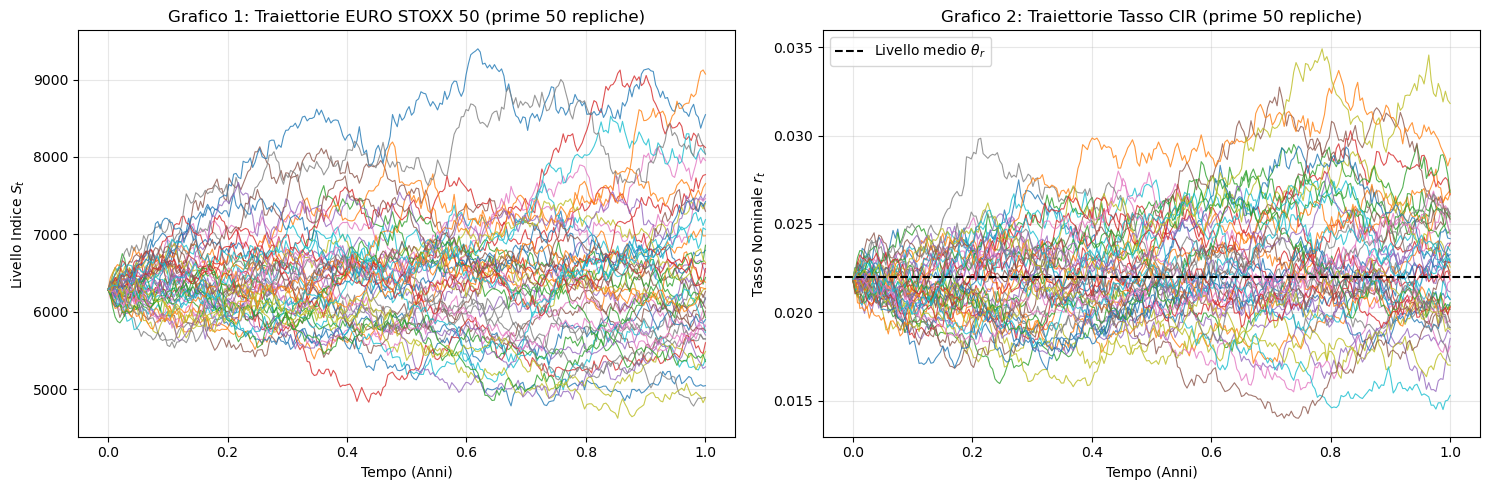

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. GENERAZIONE SHOCK E CHOLESKY
# ---------------------------------------------------------
# Estrazione di Normali Standard indipendenti per M repliche e N step
Z1 = np.random.standard_normal((M, N))
Z2 = np.random.standard_normal((M, N))

# Applicazione Cholesky
Z_S = Z1
Z_r = rho * Z1 + np.sqrt(1 - rho**2) * Z2

# ---------------------------------------------------------
# 2. CONTROLLO 1: Correlazione empirica
# ---------------------------------------------------------
# Si calcola la correlazione raggruppando tutti gli N*M shock generati
corr_empirica = np.corrcoef(Z_S.flatten(), Z_r.flatten())[0, 1]
print(f"[Controllo 1] Correlazione empirica tra gli shock (Z_S, Z_r): {corr_empirica:.4f} (Attesa: {rho})\n")

# ---------------------------------------------------------
# 3. INIZIALIZZAZIONE MATRICI E SIMULAZIONE DINAMICHE
# ---------------------------------------------------------
S = np.zeros((M, N + 1))
r = np.zeros((M, N + 1))

# Condizioni iniziali
S[:, 0] = S0
r[:, 0] = r0

# Iterazione temporale (vettorizzata sulle M repliche)
for j in range(N):
    S_old = S[:, j]
    r_old = r[:, j]
    
    # Troncamento positivo sotto radice per il CIR
    r_old_plus = np.maximum(r_old, 0.0)
    
    # Aggiornamento tasso (CIR - Euler-Maruyama)
    dr = kappa_r * (theta_r - r_old) * dt + sigma_r * np.sqrt(r_old_plus) * np.sqrt(dt) * Z_r[:, j]
    r[:, j+1] = r_old + dr
    
    # Aggiornamento sottostante (GBM exact step condizionato al tasso in t_j)
    esp = (r_old - q - 0.5 * sigma_S**2) * dt + sigma_S * np.sqrt(dt) * Z_S[:, j]
    S[:, j+1] = S_old * np.exp(esp)

# ---------------------------------------------------------
# 4. CONTROLLO 2: Positività del sottostante
# ---------------------------------------------------------
min_S = np.min(S)
print(f"[Controllo 2] Valore minimo globale del sottostante simulato: {min_S:.4f}")
if min_S > 0:
    print("              -> Condizione S_t > 0 rigorosamente soddisfatta in ogni nodo.\n")
else:
    print("              -> ANOMALIA: Condizione S_t > 0 NON soddisfatta.\n")

# ---------------------------------------------------------
# 5. CONTROLLO 3: Rilevazione e documentazione r_t < 0
# ---------------------------------------------------------
maschera_negativi = r < 0
num_negativi = np.sum(maschera_negativi)
totale_nodi = M * (N + 1)
percentuale_negativi = num_negativi / totale_nodi

if num_negativi > 0:
    print(f"[Controllo 3] Rilevati {num_negativi} valori negativi per il tasso r_t (su {totale_nodi} totali, pari al {percentuale_negativi:.6%}).")
    print("              -> I valori sono stati mantenuti nella matrice come richiesto dalla specifica numerica (nessun azzeramento forzato).")
else:
    print(f"[Controllo 3] Nessun valore negativo rilevato per il tasso r_t durante l'intera simulazione (su {totale_nodi} nodi).")

print("-" * 70)

# ---------------------------------------------------------
# 6. OUTPUT GRAFICI RICHIESTI
# ---------------------------------------------------------
# Vettore dei tempi per i grafici
t_grid = np.linspace(0, T, N + 1)
num_traiettorie_plot = 50  # Plot di un sottoinsieme per leggibilità

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Grafico 1
axes[0].plot(t_grid, S[:num_traiettorie_plot, :].T, lw=0.8, alpha=0.8)
axes[0].set_title(f"Grafico 1: Traiettorie EURO STOXX 50 (prime {num_traiettorie_plot} repliche)")
axes[0].set_xlabel("Tempo (Anni)")
axes[0].set_ylabel("Livello Indice $S_t$")
axes[0].grid(True, alpha=0.3)

# Grafico 2
axes[1].plot(t_grid, r[:num_traiettorie_plot, :].T, lw=0.8, alpha=0.8)
axes[1].axhline(y=theta_r, color='k', linestyle='--', label=r'Livello medio $\theta_r$')
axes[1].set_title(f"Grafico 2: Traiettorie Tasso CIR (prime {num_traiettorie_plot} repliche)")
axes[1].set_xlabel("Tempo (Anni)")
axes[1].set_ylabel("Tasso Nominale $r_t$")
axes[1].legend(loc="best")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Richiesta dello studente
> Sto lavorando sulla Tappa 3
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output;
> - Una cella markdown descrittiva della tappa degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva 
> - Una cella Python che esegua questa tappa 

---

### Tappa 3: Campionamento e Media Asiatica

**Obiettivo e Operazioni:**
L'obiettivo di questa tappa è quantificare l'elemento *path-dependent* dell'opzione. Per ogni singola replica Monte Carlo, si estraggono i valori del sottostante esclusivamente in corrispondenza delle 12 date di fixing mensili precedentemente calcolate. Su tali valori si applica la media aritmetica semplice per ottenere il valore finale $A_T^{(k)}$. Si estraggono inoltre i valori terminali esatti dei fattori $S_T$ e $r_T$ per fini statistici.

**Input:**
- Matrice delle traiettorie simulate del sottostante `S` e del tasso `r` (prodotte nella Tappa 2).
- Vettore degli indici dei fixing `nodi_fixing` e strike `K` (inizializzati nella Tappa 1).

**Output:**
- Vettore `A_T` contenente le medie asiatiche per ciascuna replica.
- Vettori `S_T` e `r_T` contenenti i valori terminali al tempo $T$.
- **Tabella 2:** Statistiche descrittive (media campionaria e deviazione standard campionaria) di $S_T$, $r_T$ e $A_T$.
- **Grafico 3:** Istogramma della distribuzione simulata di $A_T$, sovrapposto al livello dello strike $K$ per evidenziare visivamente la quota di repliche potenzialmente *in-the-money*.

**Controlli:**
- **Controllo 4:** Verifica matematica formale che, per ogni replica $k$, il valore della media asiatica $A_T^{(k)}$ sia compreso tra il minimo e il massimo dei valori osservati alle date di fixing della medesima replica: $\min_h S_{\tau_h}^{(k)}\leq A_T^{(k)} \leq\max_h S_{\tau_h}^{(k)}$.

**Vincoli:**
Il valore iniziale $S_0$ non deve concorrere al calcolo della media asiatica, in stretta aderenza a quanto richiesto dalla Scheda Caso.

**Uso successivo:**
Il vettore unidimensionale `A_T` generato costituisce l'input primario per la Tappa 4, nella quale verrà confrontato con lo strike $K$ per la determinazione del payoff $H_T^{(k)}$. La matrice dei tassi `r` verrà ripresa nella Tappa 4 per il calcolo del fattore di sconto.

[Controllo 4 verificato] Per ogni singola replica, la media asiatica A_T è 
                       strettamente compresa tra il minimo e il massimo dei fixing mensili.



Variabile,Media Simulata,Deviazione Standard
S_T (Sottostante a T),"6,274.5873","1,134.5572"
r_T (Tasso CIR a T),0.0219,0.0036
A_T (Media Asiatica),"6,280.0789",694.2402


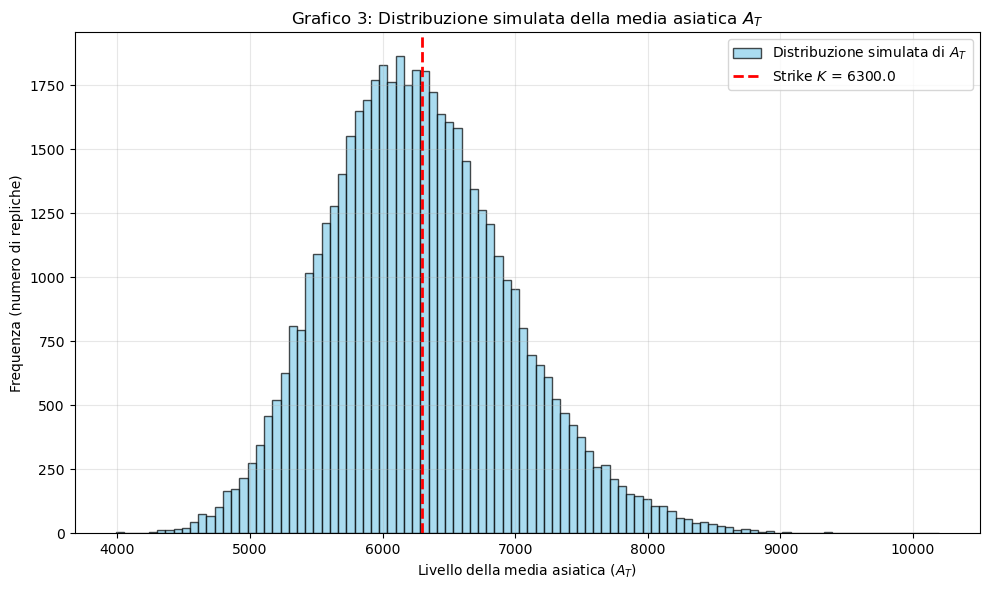

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. CAMPIONAMENTO E CALCOLO MEDIA ASIATICA
# ---------------------------------------------------------
# Estrazione dei valori del sottostante solo ai nodi di fixing (M righe, 12 colonne)
S_fixing = S[:, nodi_fixing]

# Calcolo di A_T come media aritmetica lungo le colonne per ogni riga (replica)
A_T = np.mean(S_fixing, axis=1)

# Estrazione dei valori terminali (all'istante N) per fattori
S_T = S[:, -1]
r_T = r[:, -1]

# ---------------------------------------------------------
# 2. CONTROLLO 4: Proprietà della media aritmetica
# ---------------------------------------------------------
min_S_fixing = np.min(S_fixing, axis=1)
max_S_fixing = np.max(S_fixing, axis=1)

# Verifica logica vettoriale
controllo_4_superato = np.all((A_T >= min_S_fixing) & (A_T <= max_S_fixing))

if controllo_4_superato:
    print("[Controllo 4 verificato] Per ogni singola replica, la media asiatica A_T è ")
    print("                       strettamente compresa tra il minimo e il massimo dei fixing mensili.\n")
else:
    print("[Controllo 4 FALLITO] Rilevate anomalie nel calcolo della media asiatica.\n")

# ---------------------------------------------------------
# 3. CREAZIONE E VISUALIZZAZIONE TABELLA 2
# ---------------------------------------------------------
statistiche = {
    "Variabile": ["S_T (Sottostante a T)", "r_T (Tasso CIR a T)", "A_T (Media Asiatica)"],
    "Media Simulata": [np.mean(S_T), np.mean(r_T), np.mean(A_T)],
    "Deviazione Standard": [np.std(S_T, ddof=1), np.std(r_T, ddof=1), np.std(A_T, ddof=1)]
}

tabella_2 = pd.DataFrame(statistiche)

# Formattazione per la stampa a video
format_dict = {"Media Simulata": "{:,.4f}", "Deviazione Standard": "{:,.4f}"}
display(tabella_2.style.format(format_dict).set_caption("Tabella 2: Statistiche dei fattori e della media asiatica").hide(axis="index"))

# ---------------------------------------------------------
# 4. OUTPUT GRAFICO RICHIESTO
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# Grafico 3
plt.hist(A_T, bins=100, color='skyblue', edgecolor='black', alpha=0.7, label='Distribuzione simulata di $A_T$')
plt.axvline(x=K, color='red', linestyle='--', linewidth=2, label=f'Strike $K$ = {K}')

plt.title("Grafico 3: Distribuzione simulata della media asiatica $A_T$")
plt.xlabel("Livello della media asiatica ($A_T$)")
plt.ylabel("Frequenza (numero di repliche)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Richiesta dello studente
> Sto lavorando sulla Tappa 4
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output;
> - Una cella markdown descrittiva della tappa degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva 
> - Una cella Python che esegua questa tappa 

---

### Tappa 4: Payoff e Attualizzazione Path-Dependent

**Obiettivo e Operazioni:**
L'obiettivo di questa tappa è quantificare i flussi di cassa terminali dell'opzione e attualizzarli. Per ciascuna replica Monte Carlo:
1. Si calcola il payoff asincrono della call asiatica, $H_T^{(k)} = \max(A_T^{(k)}-K, 0)$.
2. Si approssima l'integrale del tasso stocastico $r_t$ lungo l'intera traiettoria della singola replica utilizzando una somma di Riemann sinistra. Tale integrale è poi impiegato per calcolare il fattore di sconto stocastico path-dependent $\widehat D^{(k)}(0,T)$.
3. Si moltiplica il payoff per il fattore di sconto della medesima replica per ottenere il valore attualizzato $V^{(k)}$.

**Input:**
- Vettore unidimensionale `A_T` (media asiatica di ogni replica, dalla Tappa 3).
- Matrice bidimensionale `r` (traiettorie del tasso d'interesse, dalla Tappa 2).
- Parametri scalari `K` (strike), `dt` (passo di discretizzazione) ed `N` (numero di intervalli, dalla Tappa 1).

**Output:**
- Vettore `H_T` (payoff non attualizzati).
- Vettore `D` (fattori di sconto stocastici per ogni replica).
- Vettore `V` (valori attualizzati per ogni replica).
- **Grafico 4:** Istogramma della distribuzione dei valori attualizzati $V^{(k)}$, che mostra la concentrazione di massa sullo zero (repliche out-of-the-money) e la coda destra (repliche in-the-money).

**Controlli:**
- **Controllo 5:** Verifica che il payoff calcolato sia non negativo per tutte le repliche ($H_T^{(k)} \geq 0$) e rigorosamente nullo ogniqualvolta la media asiatica non superi lo strike ($A_T^{(k)} \leq K$).

[Controllo 5 verificato] H_T >= 0 per tutte le repliche ed è nullo quando A_T <= K.

[Controllo 6 verificato] Somma di Riemann calcolata correttamente su r_t0 ... r_t{N-1}.
                       Il fattore di sconto D(0,T) è strettamente positivo per ogni replica.

[Controllo 7 verificato] V^(k) = D^(k)(0,T) * H_T^(k) in tutte le repliche.

----------------------------------------------------------------------


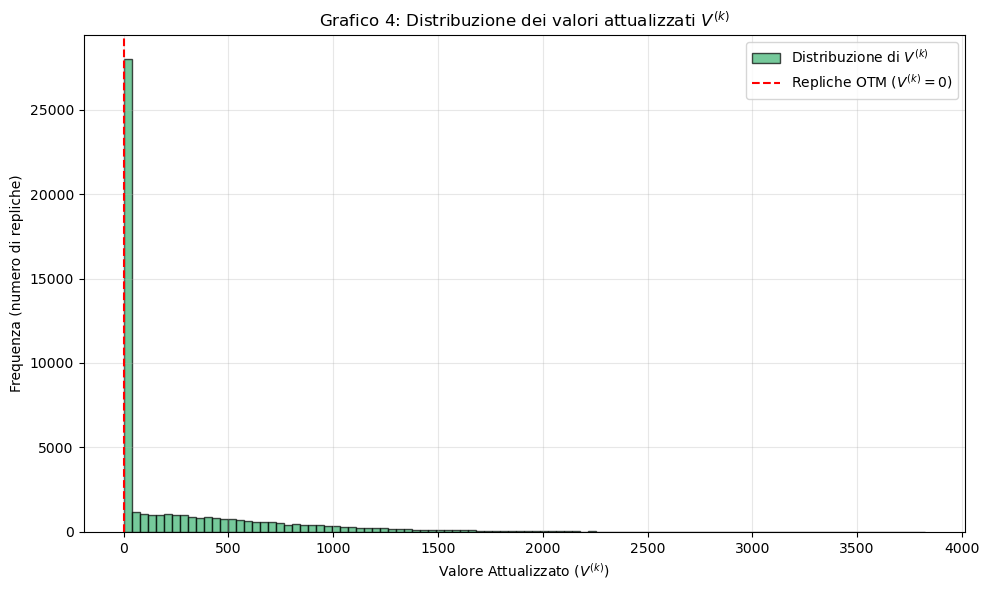

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. CALCOLO DEL PAYOFF H_T
# ---------------------------------------------------------
# Payoff della Call Asiatica (max(A_T - K, 0))
H_T = np.maximum(A_T - K, 0.0)

# ---------------------------------------------------------
# 2. CALCOLO DEL FATTORE DI SCONTO STOCASTICO
# ---------------------------------------------------------
# Estrazione dei tassi r_{t_0} ... r_{t_{N-1}} per la somma di Riemann sinistra
# La matrice r ha dimensione (M, N+1), prendiamo le prime N colonne per ogni riga
r_riemann = r[:, :N] 

# Approssimazione dell'integrale del tasso (somma per riga moltiplicata per dt)
integrale_r = np.sum(r_riemann, axis=1) * dt

# Calcolo del fattore di sconto stocastico per ciascuna replica
D = np.exp(-integrale_r)

# ---------------------------------------------------------
# 3. CALCOLO DEL VALORE ATTUALIZZATO V
# ---------------------------------------------------------
V = D * H_T

# ---------------------------------------------------------
# 4. CONTROLLO 5: Proprietà del payoff
# ---------------------------------------------------------
check_non_negativo = np.all(H_T >= 0)
check_zero_otm = np.all(H_T[A_T <= K] == 0)

if check_non_negativo and check_zero_otm:
    print("[Controllo 5 verificato] H_T >= 0 per tutte le repliche ed è nullo quando A_T <= K.\n")
else:
    print("[Controllo 5 FALLITO] Anomalie rilevate nei valori del payoff H_T.\n")

# ---------------------------------------------------------
# 5. CONTROLLO 6: Costruzione fattore di sconto
# ---------------------------------------------------------
check_positivita_D = np.all(D > 0)
# Verifica dimensionale implicita che abbiamo usato N elementi
check_dimensione_riemann = r_riemann.shape[1] == N

if check_positivita_D and check_dimensione_riemann:
    print("[Controllo 6 verificato] Somma di Riemann calcolata correttamente su r_t0 ... r_t{N-1}.")
    print("                       Il fattore di sconto D(0,T) è strettamente positivo per ogni replica.\n")
else:
    print("[Controllo 6 FALLITO] Errore nel calcolo del fattore di sconto stocastico.\n")

# ---------------------------------------------------------
# 6. CONTROLLO 7: Coerenza del valore attualizzato
# ---------------------------------------------------------
check_prodotto = np.allclose(V, D * H_T)

if check_prodotto:
    print("[Controllo 7 verificato] V^(k) = D^(k)(0,T) * H_T^(k) in tutte le repliche.\n")
else:
    print("[Controllo 7 FALLITO] Incoerenza tra V, D e H_T.\n")

print("-" * 70)

# ---------------------------------------------------------
# 7. OUTPUT GRAFICO RICHIESTO
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# Grafico 4
plt.hist(V, bins=100, color='mediumseagreen', edgecolor='black', alpha=0.7, label='Distribuzione di $V^{(k)}$')

plt.title("Grafico 4: Distribuzione dei valori attualizzati $V^{(k)}$")
plt.xlabel("Valore Attualizzato ($V^{(k)}$)")
plt.ylabel("Frequenza (numero di repliche)")

# Aggiunta di una linea per evidenziare la massa sullo zero (repliche OTM)
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Repliche OTM ($V^{(k)}=0$)')

plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Richiesta dello studente
> Sto lavorando sulla Tappa 5
> 
> Leggi la riga della tabella input-output prodotta sopra e proponi due output;
> - Una cella markdown descrittiva della tappa degli input, delle operazioni, degli output, dei controlli, dei vincoli, dei legami tra tappa precedente e tappa successiva 
> - Una cella Python che esegua questa tappa 

---

### Tappa 5: Stima Monte Carlo e Pricing

**Obiettivo e Operazioni:**
In questa tappa si esegue l'aggregazione statistica dei risultati ottenuti per le singole repliche, al fine di produrre le stime finali richieste dal problema. Applicando la Legge dei Grandi Numeri, si calcolano il valore medio del payoff e il prezzo Monte Carlo $\widehat V_M$. Avvalendosi del Teorema del Limite Centrale, si determinano l'errore standard della stima (SE) e l'intervallo di confidenza asintotico al $95\%$. Infine, si stima la probabilità risk-neutral di esercizio calcolando la frequenza relativa dei casi in cui l'opzione scade *in-the-money*.

**Input:**
- Vettori `V` (valori attualizzati), `H_T` (payoff) e `A_T` (media asiatica), tutti di dimensione $M$, calcolati nella Tappa 4 e 3.
- Parametri scalari `M` (numero di repliche) e `K` (strike), inizializzati nella Tappa 1.

**Output:**
- Stime puntuali: probabilità simulata di esercizio, payoff medio, prezzo Monte Carlo $\widehat V_M$, errore standard (SE).
- **Tabella 3 (Sintesi del payoff e del pricing):** Tabella riassuntiva che consolida le quantità probabilistiche e finanziarie richieste dalla Scheda Caso.

**Controlli:**
- **Controllo visivo (Coerenza stime):** Verifica logica sulla coerenza dell'intervallo di confidenza al $95\%$, assicurandosi che la semi-ampiezza sia correttamente pari a $1,96 \times SE$ e che le stime abbiano un ordine di grandezza plausibile rispetto allo strike e alla natura del derivato.

**Vincoli:**
La deviazione standard deve essere calcolata sui valori attualizzati $V^{(k)}$ per ottenere il corretto SE del prezzo. La probabilità simulata deve essere calcolata sotto la misura $\mathbb Q$ generata dal modello stocastico.

**Uso successivo:**
La stima baseline del prezzo ottenuta su $M = 50.000$ e la sua logica di calcolo costituiscono il riferimento per la Tappa 6, in cui si analizzerà la robustezza numerica del modello variando la numerosità delle simulazioni $M$ e testando la stabilità temporale.

In [8]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1. CALCOLO DELLE QUANTITÀ STATISTICHE E DI PRICING
# ---------------------------------------------------------
# Probabilità simulata di esercizio Q(A_T > K)
prob_esercizio = np.mean(A_T > K)

# Valore medio del payoff non attualizzato
payoff_medio = np.mean(H_T)

# Prezzo Monte Carlo (media campionaria dei valori attualizzati)
V_M = np.mean(V)

# Deviazione standard campionaria dei valori attualizzati (ddof=1 per stima corretta)
s_V = np.std(V, ddof=1)

# Errore standard (SE) della stima Monte Carlo
SE = s_V / np.sqrt(M)

# Intervallo di confidenza al 95%
IC_inferiore = V_M - 1.96 * SE
IC_superiore = V_M + 1.96 * SE

# ---------------------------------------------------------
# 2. CREAZIONE E VISUALIZZAZIONE TABELLA 3
# ---------------------------------------------------------
dati_pricing = {
    "Quantità Stimata": [
        "Probabilità simulata di esercizio Q(A_T > K)",
        "Payoff medio non attualizzato (H_T)",
        "Prezzo Monte Carlo stimato (V_M)",
        "Errore Standard Monte Carlo (SE)",
        "Limite inferiore IC 95%",
        "Limite superiore IC 95%"
    ],
    "Valore": [
        prob_esercizio,
        payoff_medio,
        V_M,
        SE,
        IC_inferiore,
        IC_superiore
    ]
}

tabella_3 = pd.DataFrame(dati_pricing)

# Formattazione per la stampa a video (percentuale per probabilità, 4 decimali per gli altri)
def format_valori(row):
    if "Probabilità" in row['Quantità Stimata']:
        return f"{row['Valore']:.2%}"
    else:
        return f"{row['Valore']:,.4f}"

tabella_3['Valore Formattato'] = tabella_3.apply(format_valori, axis=1)
tabella_3_display = tabella_3[['Quantità Stimata', 'Valore Formattato']]

display(tabella_3_display.style.set_caption("Tabella 3: Sintesi del payoff e del pricing").hide(axis="index"))

# ---------------------------------------------------------
# 3. CONTROLLO VISIVO DI COERENZA
# ---------------------------------------------------------
semi_ampiezza = (IC_superiore - IC_inferiore) / 2
print("\n[Controllo di Coerenza]")
print(f"Stima Centrale (Prezzo): {V_M:.4f}")
print(f"Semi-ampiezza IC 95% calcolata: {semi_ampiezza:.4f} (deve corrispondere a 1.96 * SE = {1.96 * SE:.4f})")
print(f"L'intervallo di confidenza [{IC_inferiore:.4f}, {IC_superiore:.4f}] risulta regolarmente calcolato e centrato sulla stima.")

Quantità Stimata,Valore Formattato
Probabilità simulata di esercizio Q(A_T > K),46.19%
Payoff medio non attualizzato (H_T),265.7366
Prezzo Monte Carlo stimato (V_M),260.1725
Errore Standard Monte Carlo (SE),1.8855
Limite inferiore IC 95%,256.4768
Limite superiore IC 95%,263.8681



[Controllo di Coerenza]
Stima Centrale (Prezzo): 260.1725
Semi-ampiezza IC 95% calcolata: 3.6957 (deve corrispondere a 1.96 * SE = 3.6957)
L'intervallo di confidenza [256.4768, 263.8681] risulta regolarmente calcolato e centrato sulla stima.


### 8. Interpretazione finale

Nel complesso il rapporto studente-IA è risultato proficuo. 

Per quanto riguarda l'interpretazione concettuale ho rilevato la seguente conclusione. 

Con il dividend yield impostato così vicino al valore medio del processo stocastico utilizzato per descrivere il tasso nominale, i risultati sono coerenti. La crescita è vicina allo zero, e la probabilità di superare lo strike, che era impostato molto vicino al valore iniziale, è coerentemente vicina al 50%.